RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =           13     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  3.91361D-01    |proj g|=  8.01078D+00


 This problem is unconstrained.



At iterate    5    f=  2.75350D-01    |proj g|=  2.92364D+00

At iterate   10    f=  1.24935D-01    |proj g|=  1.43791D+00

At iterate   15    f=  1.04043D-01    |proj g|=  1.03631D+00

At iterate   20    f=  9.50352D-02    |proj g|=  3.08323D-01

At iterate   25    f=  8.72465D-02    |proj g|=  2.17453D+00

At iterate   30    f=  8.44478D-02    |proj g|=  1.01672D+00

At iterate   35    f=  8.14944D-02    |proj g|=  4.19586D-01

At iterate   40    f=  8.12509D-02    |proj g|=  4.26001D-02

At iterate   45    f=  7.45106D-02    |proj g|=  1.56069D+00

At iterate   50    f=  5.73785D-02    |proj g|=  7.59259D-01

           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cauchy searches
Skip  = number of BFGS updates skipped
Nact  = number of active bounds at final generalized Cauchy point
Projg = norm of the final projected gradient
F     = final function value

           * * *

   N    Tit     Tn

/Users/visjostr/school/parking-prediction/.venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


Sarima MAE: 196.4381720517703, RMSE: 243.49028472256379


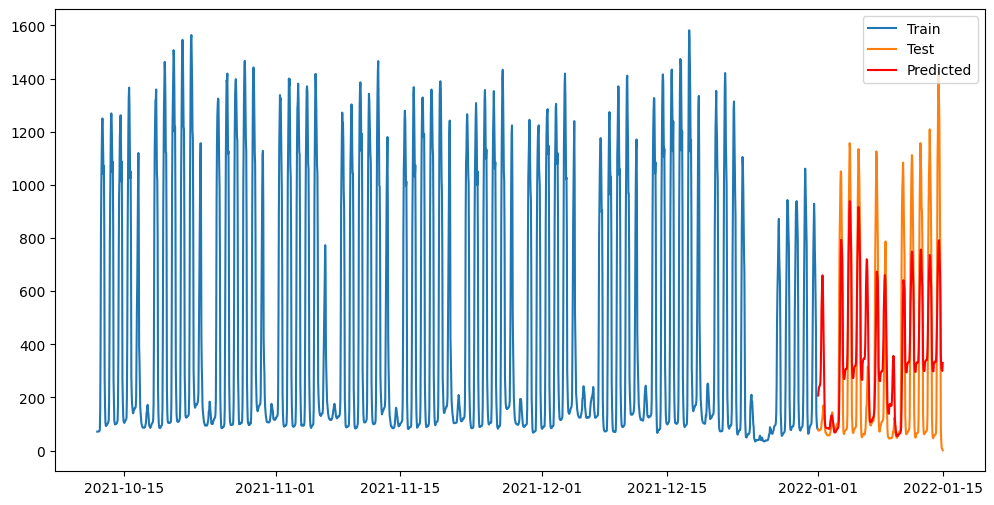

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from datetime import datetime
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Load the dataset
df = pd.read_csv('../preprocess/parking_time_series_with_features_1_hour.csv', delimiter=',')

# Parse the 'Time' column to datetime and set it as index
df['Time'] = pd.to_datetime(df['Time'])
df.set_index('Time', inplace=True)
df.sort_index(inplace=True)

# Downsample the data to hourly frequency
df_hourly = df.resample('h').mean()

# Convert exogenous features to appropriate data types
df_hourly['day_of_year'] = df_hourly['day_of_year'].astype(int)
df_hourly['weekday'] = df_hourly['weekday'].astype(int)
df_hourly['hour'] = df_hourly['hour'].astype(int)
df_hourly['is_holiday'] = df_hourly['is_holiday'].astype(int)

exogenous_features = ["day_of_year", "weekday", "hour", "is_holiday"]

# Make the time series data stationary using rolling mean and standard deviation
rolling_window = 24  # 24-hour window for hourly data
df_hourly['Parkings_rolling_mean'] = df_hourly['Parkings'].rolling(window=rolling_window).mean()
df_hourly['Parkings_rolling_std'] = df_hourly['Parkings'].rolling(window=rolling_window).std()
df_hourly['Parkings_stationary'] = (df_hourly['Parkings'] - df_hourly['Parkings_rolling_mean']) / df_hourly['Parkings_rolling_std']

# Drop NaN values resulting from rolling calculations
df_hourly.dropna(inplace=True)

# Split the data into training and test sets
end_date = datetime(2022, 1, 1)
train_data = df_hourly[df_hourly.index < end_date]
test_data = df_hourly[df_hourly.index >= end_date]

# Ensure the training data index has a frequency set
train_data.index = pd.DatetimeIndex(train_data.index.values, freq='h')  # 'h' stands for hourly frequency

# Extract exogenous features for training and test sets
train_exog = train_data[exogenous_features]
test_exog = test_data[exogenous_features]

# Define SARIMA model parameters (p, d, q) and seasonal parameters (P, D, Q, m)
p = 4
d = 0
q = 2
P = 1
D = 0
Q = 1
m = 24  # Daily seasonality in hourly data

# Fit the SARIMA model on the stationary data with exogenous features
model = SARIMAX(train_data['Parkings_stationary'], 
                order=(p, d, q), 
                seasonal_order=(P, D, Q, m),
                exog=train_exog)
sarima_results = model.fit()


# Predict using the fitted model with exogenous features
predictions_stationary = sarima_results.predict(start=test_data.index[0], end=test_data.index[-1], exog=test_exog, dynamic=False)

# Invert the transformations to return to the original scale
predictions_rolling_mean_reversed = predictions_stationary * test_data['Parkings_rolling_std'] + test_data['Parkings_rolling_mean']

# Calculate error metrics
mae_prophet = mean_absolute_error(test_data['Parkings'], predictions_rolling_mean_reversed)
rmse_prophet = np.sqrt(mean_squared_error(test_data['Parkings'], predictions_rolling_mean_reversed))

print(f'Sarima MAE: {mae_prophet}, RMSE: {rmse_prophet}')

# Plot the actual vs predicted values
plt.figure(figsize=(12, 6))
plt.plot(train_data.index, train_data['Parkings'], label='Train')
plt.plot(test_data.index, test_data['Parkings'], label='Test')
plt.plot(test_data.index, predictions_rolling_mean_reversed, label='Predicted', color='red')
plt.legend()
plt.show()


/var/folders/_t/33m89lx52y9c7bp76k6_d441b8cfj1/T/ipykernel_68150/4222111122.py:42: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  train_data.index = pd.DatetimeIndex(train_data.index.values, freq='15T')  # '15T' stands for 15-minute frequency
/Users/visjostr/school/parking-prediction/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/Users/visjostr/school/parking-prediction/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
 This problem is unconstrained.


RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =           13     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  4.96274D+01    |proj g|=  6.88576D+02

At iterate    5    f=  1.17106D+00    |proj g|=  7.37257D-01

At iterate   10    f=  1.06057D+00    |proj g|=  1.50764D+01

At iterate   15    f=  4.84613D-01    |proj g|=  7.58549D+01

At iterate   20    f= -1.42356D-01    |proj g|=  3.80192D+00

At iterate   25    f= -2.76121D-01    |proj g|=  1.20630D+00

At iterate   30    f= -5.15645D-01    |proj g|=  1.95063D+00

At iterate   35    f= -5.46484D-01    |proj g|=  2.34885D+00

At iterate   40    f= -6.42607D-01    |proj g|=  5.08696D-01

At iterate   45    f= -7.19467D-01    |proj g|=  7.13830D-01


/Users/visjostr/school/parking-prediction/.venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "



At iterate   50    f= -7.45602D-01    |proj g|=  1.00047D-01

           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cauchy searches
Skip  = number of BFGS updates skipped
Nact  = number of active bounds at final generalized Cauchy point
Projg = norm of the final projected gradient
F     = final function value

           * * *

   N    Tit     Tnf  Tnint  Skip  Nact     Projg        F
   13     50     70      1     0     0   1.000D-01  -7.456D-01
  F = -0.74560188021799323     

STOP: TOTAL NO. of ITERATIONS REACHED LIMIT                 
SARIMA MAE: 213.040423742749, RMSE: 274.46672908198803


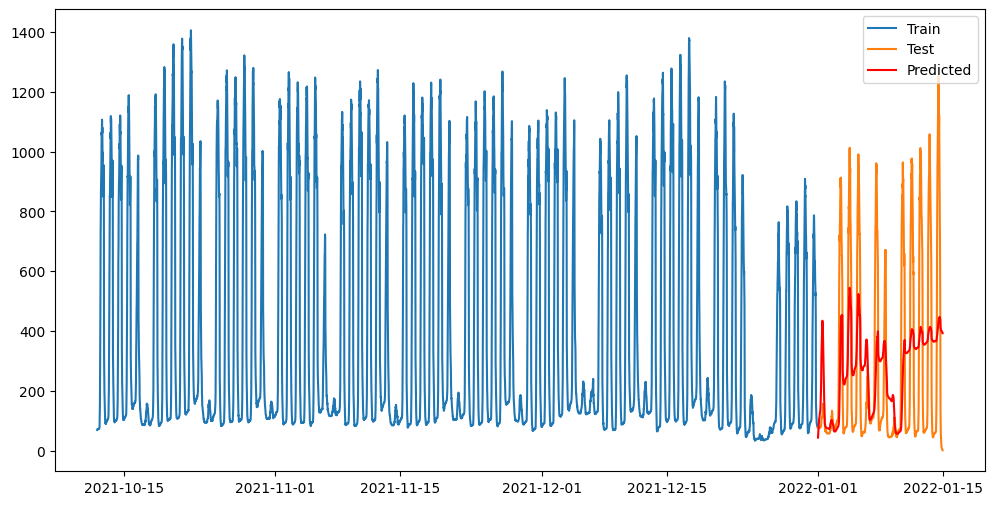

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from datetime import datetime
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Load the dataset
df = pd.read_csv('../preprocess/parking_time_series_with_features_15min.csv', delimiter=',')

# Parse the 'Time' column to datetime and set it as index
df['Time'] = pd.to_datetime(df['Time'])
df.set_index('Time', inplace=True)
df.sort_index(inplace=True)

# Downsample the data to 15-minute frequency
df_15min = df.resample('15min').mean()

# Convert exogenous features to appropriate data types
df_15min['day_of_year'] = df_15min['day_of_year'].astype(int)
df_15min['weekday'] = df_15min['weekday'].astype(int)
df_15min['hour'] = df_15min['hour'].astype(int)
df_15min['is_holiday'] = df_15min['is_holiday'].astype(int)

exogenous_features = ["day_of_year", "weekday", "hour", "is_holiday"]

# Make the time series data stationary using rolling mean and standard deviation
rolling_window = 96  # 24-hour window for 15-minute data (24 * 4)
df_15min['Parkings_rolling_mean'] = df_15min['Parkings'].rolling(window=rolling_window).mean()
df_15min['Parkings_rolling_std'] = df_15min['Parkings'].rolling(window=rolling_window).std()
df_15min['Parkings_stationary'] = (df_15min['Parkings'] - df_15min['Parkings_rolling_mean']) / df_15min['Parkings_rolling_std']

# Drop NaN values resulting from rolling calculations
df_15min.dropna(inplace=True)

# Split the data into training and test sets
end_date = datetime(2022, 1, 1)
train_data = df_15min[df_15min.index < end_date]
test_data = df_15min[df_15min.index >= end_date]

# Ensure the training data index has a frequency set
train_data.index = pd.DatetimeIndex(train_data.index.values, freq='15T')  # '15T' stands for 15-minute frequency

# Extract exogenous features for training and test sets
train_exog = train_data[exogenous_features]
test_exog = test_data[exogenous_features]

# Define SARIMA model parameters (p, d, q) and seasonal parameters (P, D, Q, m)
p = 4
d = 0
q = 2
P = 1
D = 0
Q = 1
m = 96  # Daily seasonality in 15-minute data (24 * 4)

# Fit the SARIMA model on the stationary data with exogenous features
model = SARIMAX(train_data['Parkings_stationary'], 
                order=(p, d, q), 
                seasonal_order=(P, D, Q, m),
                exog=train_exog)
sarima_results = model.fit()

# Predict using the fitted model with exogenous features
predictions_stationary = sarima_results.predict(start=test_data.index[0], end=test_data.index[-1], exog=test_exog, dynamic=False)

# Invert the transformations to return to the original scale
predictions_rolling_mean_reversed = predictions_stationary * test_data['Parkings_rolling_std'] + test_data['Parkings_rolling_mean']

# Calculate error metrics
mae_sarima = mean_absolute_error(test_data['Parkings'], predictions_rolling_mean_reversed)
rmse_sarima = np.sqrt(mean_squared_error(test_data['Parkings'], predictions_rolling_mean_reversed))

print(f'SARIMA MAE: {mae_sarima}, RMSE: {rmse_sarima}')

# Plot the actual vs predicted values
plt.figure(figsize=(12, 6))
plt.plot(train_data.index, train_data['Parkings'], label='Train')
plt.plot(test_data.index, test_data['Parkings'], label='Test')
plt.plot(test_data.index, predictions_rolling_mean_reversed, label='Predicted', color='red')
plt.legend()
plt.show()
